# Retail Sales: Exploratory Data Analysis

**Author:** Virendra Malviya  |  **Tools:** Python, pandas, matplotlib, seaborn

## What this notebook is about
A retail store records every sale it makes: who bought, how old they are, what category they bought from, how many units, and how much they paid. That is a small table, but it hides a lot of answers. In this notebook I try to answer five plain questions a store manager would actually care about:

1. **When** do we sell the most (and the least)?
2. **Who** are our customers (age and gender)?
3. **What** sells, and what brings in the money?
4. Which numbers move together?
5. Is there anything **not obvious** hiding in the data?

At the end I turn the findings into business recommendations.

**Dataset:** *Retail Sales Dataset* from Kaggle (`retail_sales_dataset.csv`). Put the CSV in the same folder as this notebook (or in `data/` or `archive/`).

**A note on how the observations are written:** the written observation under each chart is generated from the data itself, so the numbers always match the chart above it. If you swap in a different retail dataset with the same columns, the notebook still reads correctly.

## 0. Setup

In [19]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook", palette="viridis")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})

def say(text):
    """Render a markdown observation under a chart."""
    display(Markdown(text))

def money(x):
    return f"{x:,.0f}"

## 1. Loading the data and first inspection
Before any analysis, I want to know the size of the table, what type each column is, and whether anything is missing or duplicated.

In [20]:
candidates = [Path("retail_sales_dataset.csv"), Path("data/retail_sales_dataset.csv"),
              Path("archive/retail_sales_dataset.csv")]
path = next((p for p in candidates if p.exists()), None)
if path is None:
    raise FileNotFoundError("Place retail_sales_dataset.csv next to this notebook (or in data/ or archive/).")

raw = pd.read_csv(path)
df = raw.copy()

# tidy column names: "Price per Unit" -> "price_per_unit"
df.columns = df.columns.str.strip().str.lower().str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_")

print(f"Loaded: {path}")
print(f"Shape : {df.shape[0]:,} rows x {df.shape[1]} columns\n")
df.head()

Loaded: retail_sales_dataset.csv
Shape : 1,000 rows x 9 columns



,transaction_id,date,customer_id,gender,age,product_category,quantity,price_per_unit,total_amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [21]:
print("Column data types\n" + "-" * 30)
print(df.dtypes.to_string())

print("\nNull values per column\n" + "-" * 30)
print(df.isnull().sum().to_string())

print(f"\nDuplicate rows       : {df.duplicated().sum()}")
print(f"Duplicate transaction IDs: {df['transaction_id'].duplicated().sum()}")

Column data types
------------------------------
transaction_id      int64
date                  str
customer_id           str
gender                str
age                 int64
product_category      str
quantity            int64
price_per_unit      int64
total_amount        int64

Null values per column
------------------------------
transaction_id      0
date                0
customer_id         0
gender              0
age                 0
product_category    0
quantity            0
price_per_unit      0
total_amount        0

Duplicate rows       : 0
Duplicate transaction IDs: 0


In [22]:
# Does Total Amount really equal Quantity x Price per Unit? (a quick integrity check)
gap = (df["quantity"] * df["price_per_unit"] - df["total_amount"]).abs()
mismatch = int((gap > 0.01).sum())

say(f"""
**What I see.** The table has **{df.shape[0]:,} transactions** and **{df.shape[1]} columns**. 
Missing values in total: **{int(df.isnull().sum().sum())}**. Duplicate rows: **{int(df.duplicated().sum())}**.
`total_amount` matches `quantity × price_per_unit` in **{len(df) - mismatch:,} of {len(df):,}** rows, 
so the revenue column can be trusted. {"No cleaning is needed beyond fixing the `date` type." if df.isnull().sum().sum() == 0 else "Some nulls exist, so I will be careful when aggregating."}
""")


**What I see.** The table has **1,000 transactions** and **9 columns**. 
Missing values in total: **0**. Duplicate rows: **0**.
`total_amount` matches `quantity × price_per_unit` in **1,000 of 1,000** rows, 
so the revenue column can be trusted. No cleaning is needed beyond fixing the `date` type.


### Light feature engineering
A few helper columns make the later analysis much easier: a real datetime, month/quarter labels, weekday, and age groups (bands of ages are easier to read than 60 separate ages).

In [23]:
df["date"] = pd.to_datetime(df["date"])
df["month"] = df["date"].dt.to_period("M")
df["quarter"] = df["date"].dt.to_period("Q")
df["weekday"] = pd.Categorical(df["date"].dt.day_name(),
                               ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"],
                               ordered=True)

age_bins   = [0, 24, 34, 44, 54, 200]
age_labels = ["Under 25", "25-34", "35-44", "45-54", "55+"]
df["age_group"] = pd.cut(df["age"], bins=age_bins, labels=age_labels)

print(f"Date range: {df['date'].min().date()} to {df['date'].max().date()}")
df[["date", "month", "quarter", "weekday", "age", "age_group"]].head()

Date range: 2023-01-01 to 2024-01-01


,date,month,quarter,weekday,age,age_group
0,2023-11-24,2023-11,2023Q4,Friday,34,25-34
1,2023-02-27,2023-02,2023Q1,Monday,26,25-34
2,2023-01-13,2023-01,2023Q1,Friday,50,45-54
3,2023-05-21,2023-05,2023Q2,Sunday,37,35-44
4,2023-05-06,2023-05,2023Q2,Saturday,30,25-34


## 2. Descriptive statistics
Mean, median, mode and standard deviation for every numerical column. IDs are left out because averaging an ID has no meaning.

In [24]:
num_cols = ["age", "quantity", "price_per_unit", "total_amount"]

stats = df[num_cols].agg(["mean", "median", "std", "min", "max"]).T
stats["mode"] = df[num_cols].mode().iloc[0]
stats = stats[["mean", "median", "mode", "std", "min", "max"]].round(2)
stats

,mean,median,mode,std,min,max
age,41.39,42.0,43.0,13.68,18.0,64.0
quantity,2.51,3.0,4.0,1.13,1.0,4.0
price_per_unit,179.89,50.0,50.0,189.68,25.0,500.0
total_amount,456.00,135.0,50.0,560.00,25.0,2000.0


In [25]:
cv = (df["total_amount"].std() / df["total_amount"].mean()) * 100
skew = df["total_amount"].skew()

say(f"""
**Observations**

- **Spend per transaction:** the mean is **{stats.loc['total_amount','mean']:,.0f}** while the median is **{stats.loc['total_amount','median']:,.0f}**. 
  {"The mean sits well above the median, which tells me a minority of large purchases pull the average up." if stats.loc['total_amount','mean'] > 1.15*stats.loc['total_amount','median'] else "Mean and median are close, so spending is fairly balanced."} 
  The standard deviation is **{stats.loc['total_amount','std']:,.0f}** (about **{cv:.0f}%** of the mean, skewness {skew:.2f}), so basket sizes vary a lot from one sale to the next.
- **Customers:** the average age is **{stats.loc['age','mean']:.1f}** and the most common age is **{int(stats.loc['age','mode'])}**.
- **Quantity:** the typical purchase is **{int(stats.loc['quantity','median'])} unit(s)**, with a maximum of {int(stats.loc['quantity','max'])}. 
  So the large spread in spend comes mostly from *what* is bought (unit price), not from *how many* units.
""")


**Observations**

- **Spend per transaction:** the mean is **456** while the median is **135**. 
  The mean sits well above the median, which tells me a minority of large purchases pull the average up. 
  The standard deviation is **560** (about **123%** of the mean, skewness 1.38), so basket sizes vary a lot from one sale to the next.
- **Customers:** the average age is **41.4** and the most common age is **43**.
- **Quantity:** the typical purchase is **3 unit(s)**, with a maximum of 4. 
  So the large spread in spend comes mostly from *what* is bought (unit price), not from *how many* units.


## 3. Sales over time
Monthly and quarterly revenue. A month or quarter that the data only partly covers (for example a single day of January) would look like a fake crash, so those are excluded from the lines and mentioned below.

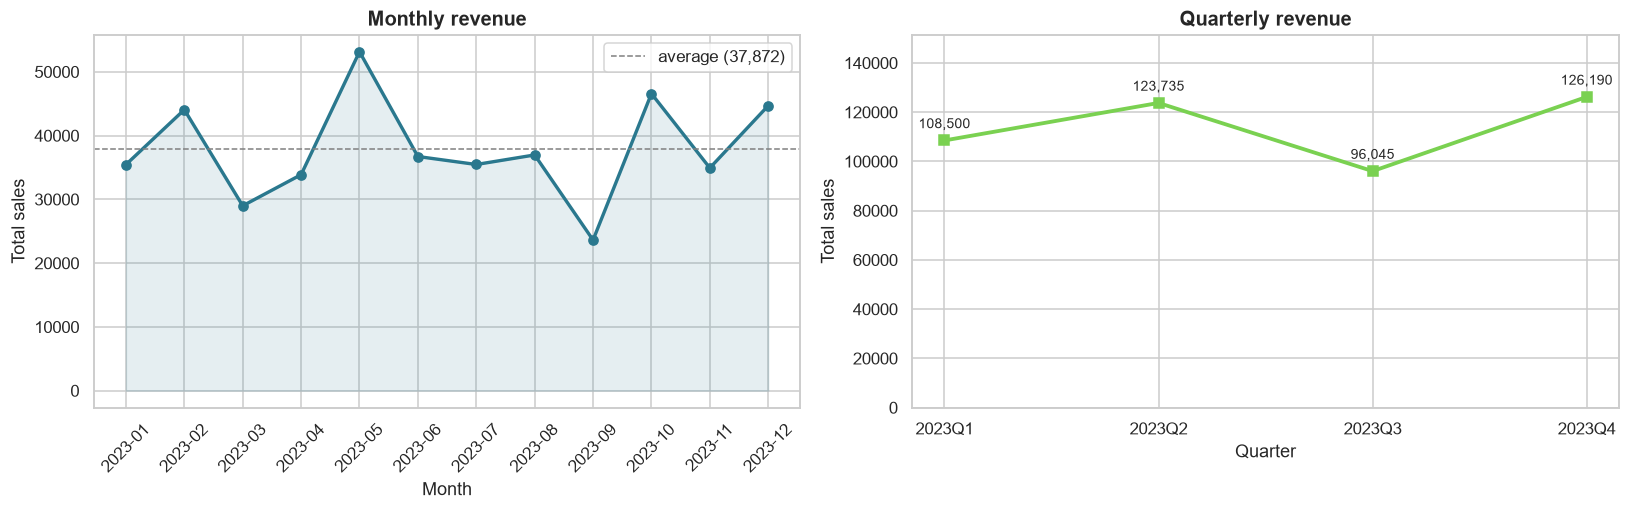

In [26]:
def coverage_filter(series, df_dates, freq):
    """Keep only periods where at least 80% of the calendar days appear in the data's date range."""
    d0, d1 = df_dates.min().normalize(), df_dates.max().normalize()
    keep = []
    for p in series.index:
        start, end = max(p.start_time.normalize(), d0), min(p.end_time.normalize(), d1)
        covered = (end - start).days + 1
        total = (p.end_time.normalize() - p.start_time.normalize()).days + 1
        keep.append(covered / total >= 0.8)
    return series[keep], series[[not k for k in keep]]

monthly_all   = df.groupby("month")["total_amount"].sum()
quarterly_all = df.groupby("quarter")["total_amount"].sum()
monthly, m_dropped   = coverage_filter(monthly_all, df["date"], "M")
quarterly, q_dropped = coverage_filter(quarterly_all, df["date"], "Q")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

axes[0].plot(monthly.index.astype(str), monthly.values, marker="o", lw=2.2, color="#2a788e")
axes[0].fill_between(range(len(monthly)), monthly.values, alpha=0.12, color="#2a788e")
axes[0].axhline(monthly.mean(), ls="--", color="grey", lw=1, label=f"average ({money(monthly.mean())})")
axes[0].set(title="Monthly revenue", xlabel="Month", ylabel="Total sales")
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend()

axes[1].plot(quarterly.index.astype(str), quarterly.values, marker="s", lw=2.5, color="#7ad151")
for x, y in zip(quarterly.index.astype(str), quarterly.values):
    axes[1].annotate(money(y), (x, y), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
axes[1].set(title="Quarterly revenue", xlabel="Quarter", ylabel="Total sales")
axes[1].set_ylim(0, quarterly.max() * 1.2)

plt.tight_layout()
plt.show()

In [27]:
peak_m, low_m = monthly.idxmax(), monthly.idxmin()
best_q, worst_q = quarterly.idxmax(), quarterly.idxmin()
spread = (monthly.max() - monthly.min()) / monthly.mean() * 100
mom = monthly.pct_change().dropna() * 100
biggest_jump, biggest_drop = mom.idxmax(), mom.idxmin()
dropped_note = ""
if len(m_dropped) or len(q_dropped):
    dropped_note = f"\n- Left out as only partly covered: months {[str(p) for p in m_dropped.index]}, quarters {[str(p) for p in q_dropped.index]}."

say(f"""
**Observations**

- The **strongest month is {peak_m}** ({money(monthly.max())}) and the **weakest is {low_m}** ({money(monthly.min())}). 
  The gap between them is about **{spread:.0f}% of an average month**, so sales are {"clearly uneven across the year" if spread > 40 else "fairly steady across the year"}.
- Month-to-month, the biggest rise was into **{biggest_jump}** (**{mom.max():+.0f}%**) and the biggest fall was into **{biggest_drop}** (**{mom.min():+.0f}%**).
- By quarter, **{best_q}** is the best ({money(quarterly.max())}) and **{worst_q}** the weakest ({money(quarterly.min())}).{dropped_note}
- Caution: with only about one year of data I can see *swings*, but I cannot prove they are *seasonal*. That would need at least two years.
""")


**Observations**

- The **strongest month is 2023-05** (53,150) and the **weakest is 2023-09** (23,620). 
  The gap between them is about **78% of an average month**, so sales are clearly uneven across the year.
- Month-to-month, the biggest rise was into **2023-10** (**+97%**) and the biggest fall was into **2023-09** (**-36%**).
- By quarter, **2023Q4** is the best (126,190) and **2023Q3** the weakest (96,045).
- Left out as only partly covered: months ['2024-01'], quarters ['2024Q1'].
- Caution: with only about one year of data I can see *swings*, but I cannot prove they are *seasonal*. That would need at least two years.


## 4. Who are the customers?
Age distribution, age groups, and the gender split, both by number of transactions and by money spent.

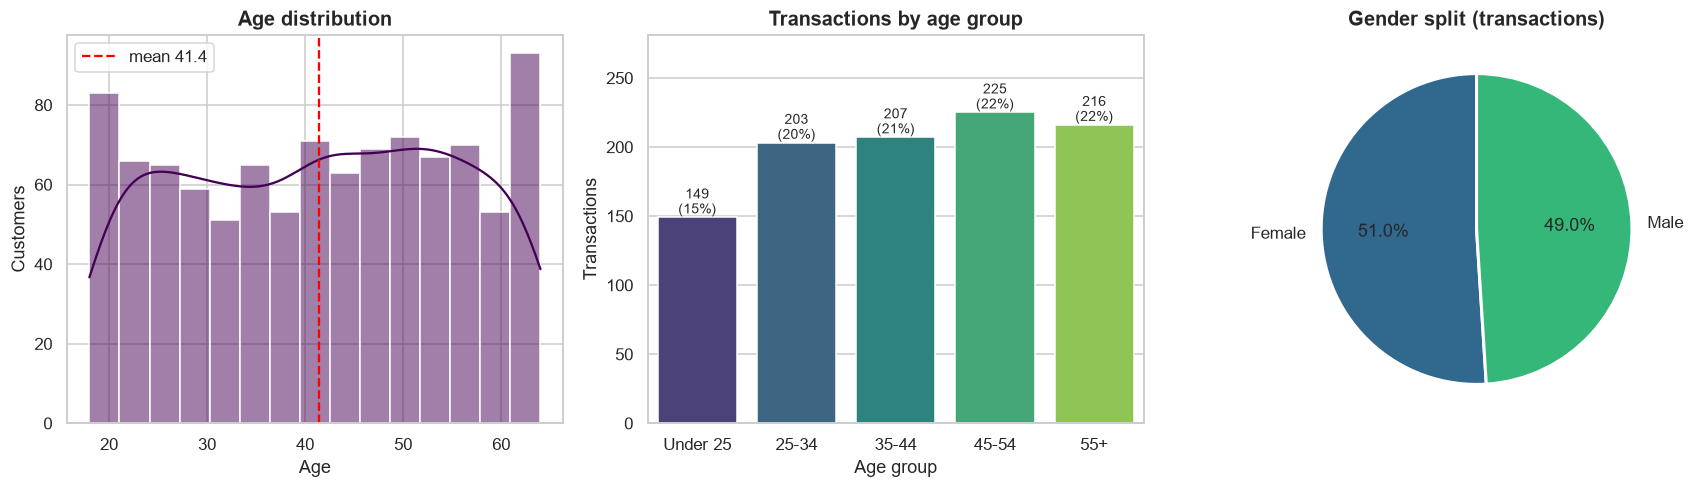

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

sns.histplot(df["age"], bins=15, kde=True, color="#440154", ax=axes[0])
axes[0].axvline(df["age"].mean(), color="red", ls="--", label=f"mean {df['age'].mean():.1f}")
axes[0].set(title="Age distribution", xlabel="Age", ylabel="Customers")
axes[0].legend()

ag = df["age_group"].value_counts().reindex(age_labels)
sns.barplot(x=ag.index, y=ag.values, ax=axes[1], palette="viridis")
for i, v in enumerate(ag.values):
    axes[1].text(i, v, f"{v}\n({v/len(df)*100:.0f}%)", ha="center", va="bottom", fontsize=9)
axes[1].set(title="Transactions by age group", xlabel="Age group", ylabel="Transactions")
axes[1].set_ylim(0, ag.max() * 1.25)

gc = df["gender"].value_counts()
axes[2].pie(gc.values, labels=gc.index, autopct="%1.1f%%", startangle=90,
            colors=["#31688e", "#35b779"], wedgeprops={"edgecolor": "white", "linewidth": 2})
axes[2].set_title("Gender split (transactions)")

plt.tight_layout()
plt.show()

In [29]:
rev_gender = df.groupby("gender")["total_amount"].agg(["sum", "mean", "count"]).round(0)
rev_agegrp = df.groupby("age_group")["total_amount"].agg(["sum", "mean", "count"]).round(0)
display(rev_gender.rename(columns={"sum": "total revenue", "mean": "avg per transaction", "count": "transactions"}))
display(rev_agegrp.rename(columns={"sum": "total revenue", "mean": "avg per transaction", "count": "transactions"}))

top_ag = ag.idxmax()
rich_ag = rev_agegrp["mean"].idxmax()
g_top = gc.idxmax()
g_rev_top = rev_gender["sum"].idxmax()
g_gap = abs(gc.iloc[0] - gc.iloc[1]) / len(df) * 100
spend_gap = (rev_gender["mean"].max() / rev_gender["mean"].min() - 1) * 100

say(f"""
**Observations**

- Ages run from **{df['age'].min()} to {df['age'].max()}**, and the histogram is {"fairly flat, i.e. no single age dominates" if df['age'].std() > 12 else "concentrated around the middle"}. 
  The largest group by head-count is **{top_ag}** ({ag.max()/len(df)*100:.0f}% of transactions).
- By **average spend per transaction**, the leading age group is **{rich_ag}** ({rev_agegrp.loc[rich_ag,'mean']:,.0f}), which is not necessarily the same as the largest group by head-count.
- **Gender:** the split is **{gc.iloc[0]/len(df)*100:.1f}% {gc.index[0]}** vs **{gc.iloc[1]/len(df)*100:.1f}% {gc.index[1]}**, a gap of only {g_gap:.1f} percentage points. 
  **{g_rev_top}** customers bring in more total revenue, and average spend per transaction differs by about **{spend_gap:.0f}%** between the two groups.
""")

,total revenue,avg per transaction,transactions
gender,,,
Female,232840,457.0,510
Male,223160,455.0,490


,total revenue,avg per transaction,transactions
age_group,,,
Under 25,74650,501.0,149
25-34,97090,478.0,203
35-44,96835,468.0,207
45-54,97235,432.0,225
55+,90190,418.0,216



**Observations**

- Ages run from **18 to 64**, and the histogram is fairly flat, i.e. no single age dominates. 
  The largest group by head-count is **45-54** (22% of transactions).
- By **average spend per transaction**, the leading age group is **Under 25** (501), which is not necessarily the same as the largest group by head-count.
- **Gender:** the split is **51.0% Female** vs **49.0% Male**, a gap of only 2.0 percentage points. 
  **Female** customers bring in more total revenue, and average spend per transaction differs by about **0%** between the two groups.


## 5. Products and categories
**A small honest note:** this dataset has product *categories* and a *price per unit*, but no product names. So for "top 10 best-selling products" I define a product as **a category at a given price point** (for example *Clothing @ 50*). If your copy of the data has a `product_name` column, the code below uses that instead.

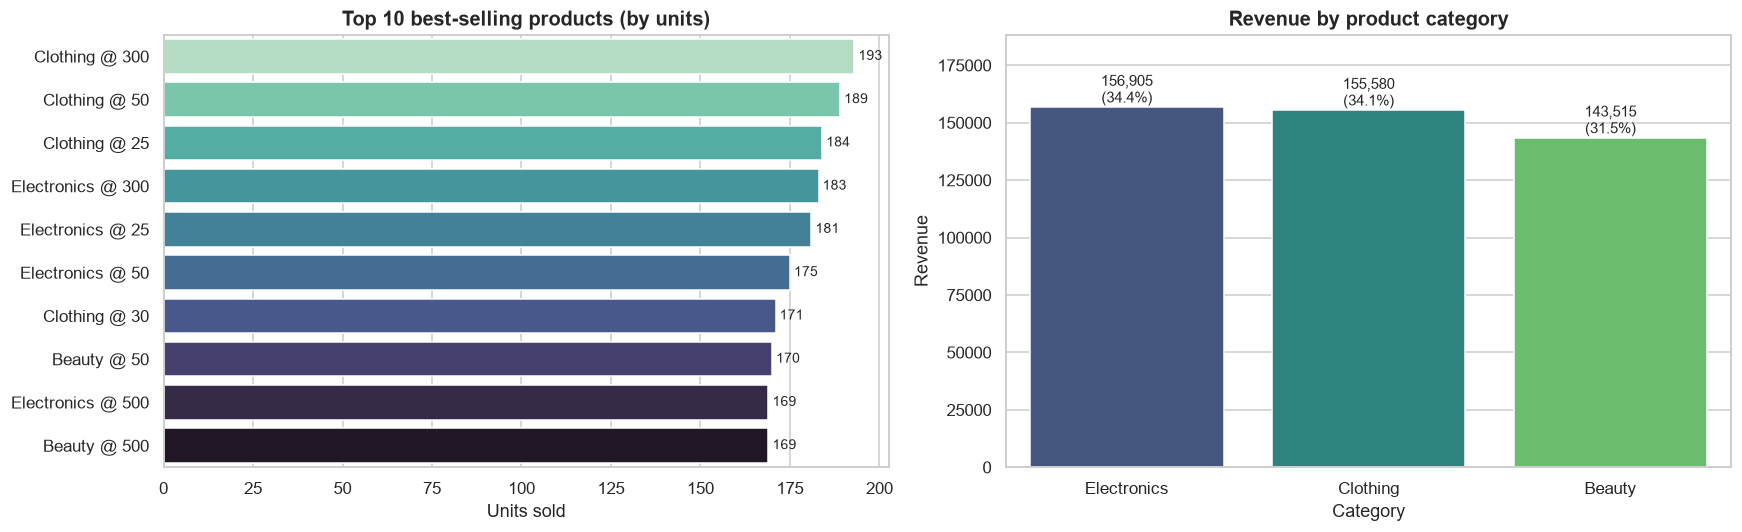

,revenue,units,orders,share_%
product_category,,,,
Electronics,156905,849,342,34.4
Clothing,155580,894,351,34.1
Beauty,143515,771,307,31.5


In [30]:
if "product_name" in df.columns:
    df["product"] = df["product_name"]
else:
    df["product"] = df["product_category"] + " @ " + df["price_per_unit"].astype(int).astype(str)

top10 = (df.groupby("product")
           .agg(units_sold=("quantity", "sum"), revenue=("total_amount", "sum"))
           .sort_values("units_sold", ascending=False).head(10))

cat_rev = (df.groupby("product_category")
             .agg(revenue=("total_amount", "sum"), units=("quantity", "sum"), orders=("transaction_id", "count"))
             .sort_values("revenue", ascending=False))
cat_rev["share_%"] = (cat_rev["revenue"] / cat_rev["revenue"].sum() * 100).round(1)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(y=top10.index, x=top10["units_sold"], ax=axes[0], palette="mako_r")
for i, v in enumerate(top10["units_sold"]):
    axes[0].text(v, i, f" {v}", va="center", fontsize=9)
axes[0].set(title="Top 10 best-selling products (by units)", xlabel="Units sold", ylabel="")

sns.barplot(x=cat_rev.index, y=cat_rev["revenue"], ax=axes[1], palette="viridis")
for i, (v, s) in enumerate(zip(cat_rev["revenue"], cat_rev["share_%"])):
    axes[1].text(i, v, f"{money(v)}\n({s}%)", ha="center", va="bottom", fontsize=10)
axes[1].set(title="Revenue by product category", xlabel="Category", ylabel="Revenue")
axes[1].set_ylim(0, cat_rev["revenue"].max() * 1.2)

plt.tight_layout()
plt.show()
cat_rev

In [31]:
top_prod = top10.index[0]
top_rev_prod = top10["revenue"].idxmax()
lead_cat, last_cat = cat_rev.index[0], cat_rev.index[-1]
cat_orders_top = cat_rev["orders"].idxmax()
cat_gap = (cat_rev["revenue"].iloc[0] / cat_rev["revenue"].iloc[-1] - 1) * 100

say(f"""
**Observations**

- The most-sold product is **{top_prod}** ({top10.loc[top_prod,'units_sold']} units), but the one that earns the most among the top 10 is **{top_rev_prod}** ({money(top10.loc[top_rev_prod,'revenue'])}). 
  **Selling the most units and earning the most money are different things.**
- By revenue, **{lead_cat}** leads with **{cat_rev.loc[lead_cat,'share_%']}%** of sales and **{last_cat}** trails with {cat_rev.loc[last_cat,'share_%']}%; the gap is about **{cat_gap:.0f}%**.
- The category with the most *orders* is **{cat_orders_top}**. {"That is also the revenue leader." if cat_orders_top == lead_cat else "That is not the revenue leader, so order count alone is a misleading way to rank categories."}
""")


**Observations**

- The most-sold product is **Clothing @ 300** (193 units), but the one that earns the most among the top 10 is **Electronics @ 500** (84,500). 
  **Selling the most units and earning the most money are different things.**
- By revenue, **Electronics** leads with **34.4%** of sales and **Beauty** trails with 31.5%; the gap is about **9%**.
- The category with the most *orders* is **Clothing**. That is not the revenue leader, so order count alone is a misleading way to rank categories.


## 6. Correlation heatmap
Which numerical variables move together? Pearson correlation runs from -1 (opposite) through 0 (unrelated) to +1 (move together).

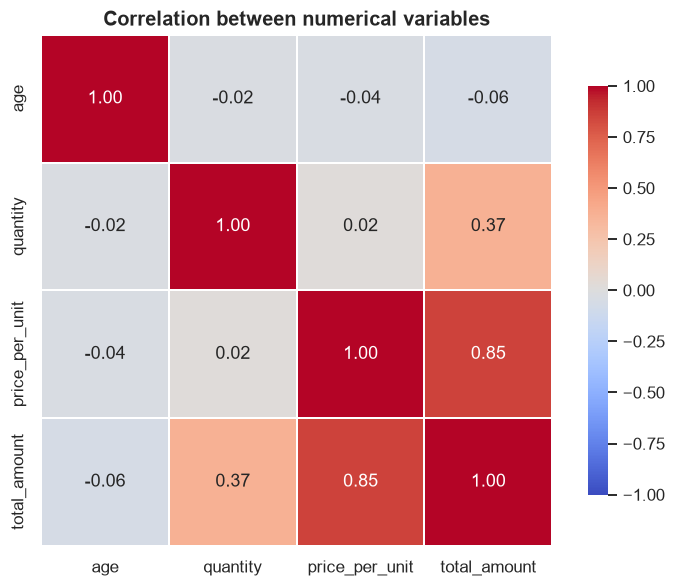

In [32]:
corr = df[num_cols].corr()

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title("Correlation between numerical variables")
plt.tight_layout()
plt.show()

In [33]:
pairs = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().dropna()
             .rename("r").reset_index().rename(columns={"level_0": "a", "level_1": "b"}))
pairs["abs_r"] = pairs["r"].abs()
pairs = pairs.sort_values("abs_r", ascending=False)
strongest, weakest = pairs.iloc[0], pairs.iloc[-1]
age_spend = corr.loc["age", "total_amount"]

say(f"""
**Observations**

- The strongest relationship is **{strongest['a']} vs {strongest['b']}** (r = **{strongest['r']:.2f}**). 
  This one is partly *by construction*, because `total_amount = quantity × price_per_unit`, so it is expected rather than a discovery.
- The weakest link is **{weakest['a']} vs {weakest['b']}** (r = {weakest['r']:.2f}), essentially unrelated.
- **Age vs total spend is r = {age_spend:.2f}.** {"That is very close to zero: how old a customer is tells us almost nothing about how much they will spend." if abs(age_spend) < 0.1 else "There is a small link between age and spend."} 
  If that holds up, blanket 'target by age' marketing is unlikely to pay off by itself; the *category and price point* matter more.
""")


**Observations**

- The strongest relationship is **price_per_unit vs total_amount** (r = **0.85**). 
  This one is partly *by construction*, because `total_amount = quantity × price_per_unit`, so it is expected rather than a discovery.
- The weakest link is **quantity vs price_per_unit** (r = 0.02), essentially unrelated.
- **Age vs total spend is r = -0.06.** That is very close to zero: how old a customer is tells us almost nothing about how much they will spend. 
  If that holds up, blanket 'target by age' marketing is unlikely to pay off by itself; the *category and price point* matter more.


## 7. Digging for something non-obvious
Two questions that the charts so far cannot answer on their own:

- **Left:** does the *same* age group spend differently depending on the *category*? (average spend per transaction, age group × category)
- **Right:** are *premium-priced* items (unit price above the dataset median) a big share of sales by **count** or by **money**?

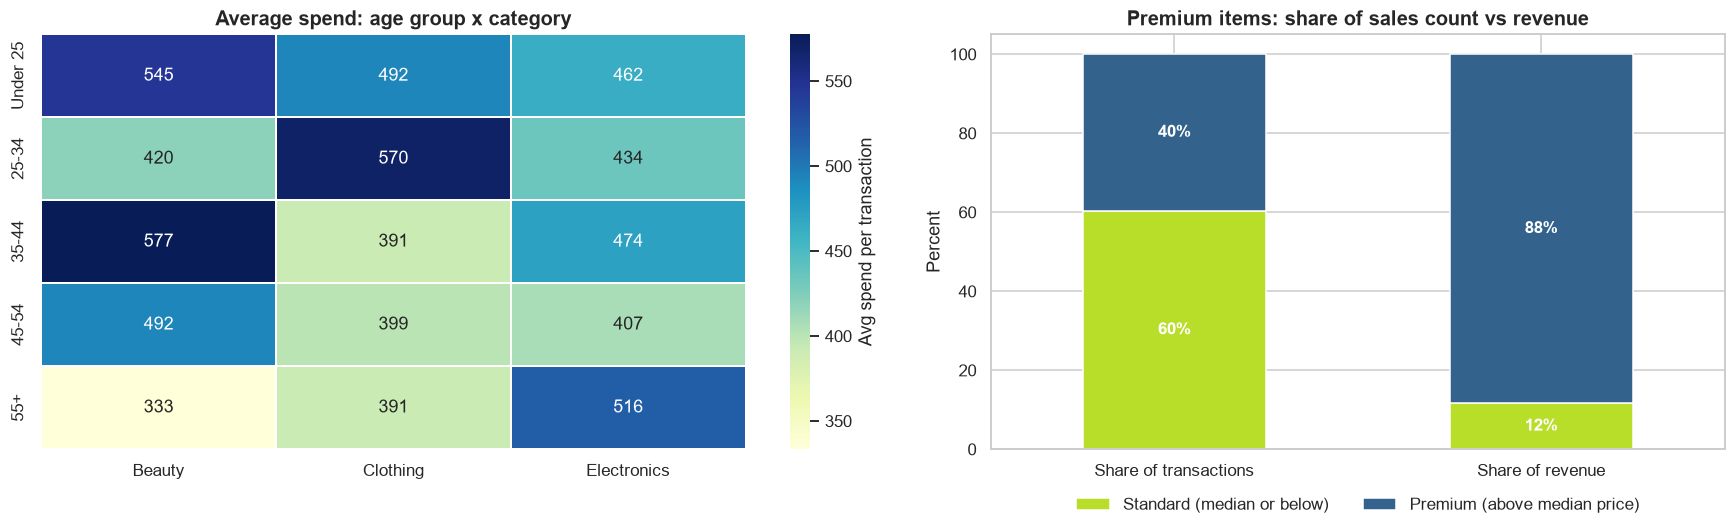

In [34]:
pivot = df.pivot_table(index="age_group", columns="product_category", values="total_amount", aggfunc="mean").reindex(age_labels)

median_price = df["price_per_unit"].median()
df["tier"] = np.where(df["price_per_unit"] > median_price, "Premium (above median price)", "Standard (median or below)")
share = pd.DataFrame({
    "Share of transactions": df["tier"].value_counts(normalize=True) * 100,
    "Share of revenue": df.groupby("tier")["total_amount"].sum() / df["total_amount"].sum() * 100,
}).T[["Standard (median or below)", "Premium (above median price)"]]

fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1.2, 1]})

sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlGnBu", linewidths=1, ax=axes[0], cbar_kws={"label": "Avg spend per transaction"})
axes[0].set(title="Average spend: age group x category", xlabel="", ylabel="")

share.plot(kind="bar", stacked=True, ax=axes[1], color=["#b8de29", "#33638d"], edgecolor="white")
for c in axes[1].containers:
    axes[1].bar_label(c, fmt="%.0f%%", label_type="center", color="white", fontsize=11, fontweight="bold")
axes[1].set(title="Premium items: share of sales count vs revenue", ylabel="Percent", xlabel="")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False)

plt.tight_layout()
plt.show()

In [35]:
stack = pivot.stack()
best_cell, worst_cell = stack.idxmax(), stack.idxmin()
prem_n = share.loc["Share of transactions", "Premium (above median price)"]
prem_r = share.loc["Share of revenue", "Premium (above median price)"]
row_swing = (pivot.max(axis=1) - pivot.min(axis=1)).idxmax()

say(f"""
**Observations**

- **Heatmap:** the highest-spending pocket is **{best_cell[0]} buying {best_cell[1]}** ({stack.max():,.0f} per transaction) and the lowest is **{worst_cell[0]} buying {worst_cell[1]}** ({stack.min():,.0f}). 
  The age group with the widest swing between categories is **{row_swing}**. So the age-vs-spend picture from the correlation table hides real differences *inside* categories.
- **Premium items:** they make up only **{prem_n:.0f}%** of transactions but bring in **{prem_r:.0f}%** of revenue. 
  A small number of high-priced sales carries most of the money, so losing a handful of premium sales hurts far more than losing many cheap ones.
""")


**Observations**

- **Heatmap:** the highest-spending pocket is **35-44 buying Beauty** (577 per transaction) and the lowest is **55+ buying Beauty** (333). 
  The age group with the widest swing between categories is **35-44**. So the age-vs-spend picture from the correlation table hides real differences *inside* categories.
- **Premium items:** they make up only **40%** of transactions but bring in **88%** of revenue. 
  A small number of high-priced sales carries most of the money, so losing a handful of premium sales hurts far more than losing many cheap ones.


### One more quick check: which days of the week are busy?
Cheap to check, and useful for staffing and promotions.

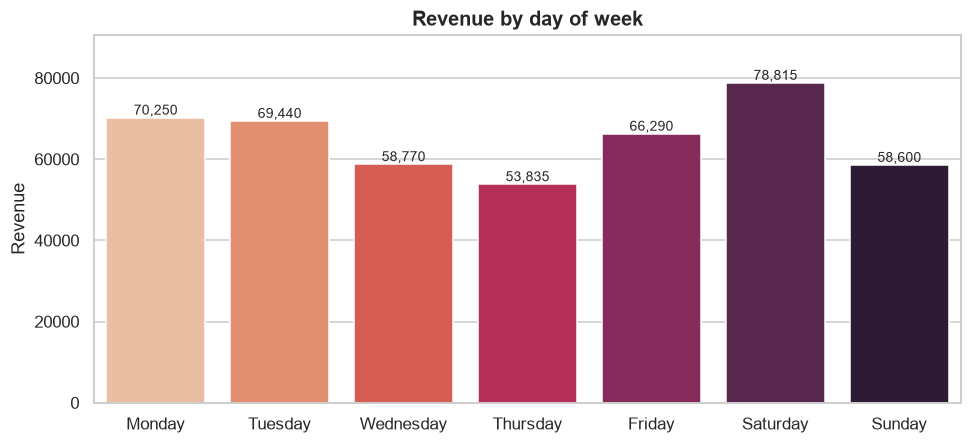


**Observation:** **Saturday** is the best day (78,815) and **Thursday** the quietest (53,835), 
a difference of 46%. That is a meaningful gap.


In [36]:
wd = df.groupby("weekday")["total_amount"].agg(["sum", "count"])
fig, ax = plt.subplots(figsize=(9, 4.2))
sns.barplot(x=wd.index.astype(str), y=wd["sum"], ax=ax, palette="rocket_r")
ax.set(title="Revenue by day of week", xlabel="", ylabel="Revenue")
ax.set_ylim(0, wd["sum"].max() * 1.15)
for i, v in enumerate(wd["sum"]):
    ax.text(i, v, money(v), ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

best_d, worst_d = wd["sum"].idxmax(), wd["sum"].idxmin()
say(f"""
**Observation:** **{best_d}** is the best day ({money(wd['sum'].max())}) and **{worst_d}** the quietest ({money(wd['sum'].min())}), 
a difference of {(wd['sum'].max()/wd['sum'].min()-1)*100:.0f}%. {"That is a meaningful gap." if wd['sum'].max()/wd['sum'].min() > 1.25 else "Days are quite even, so weekday is not a strong lever."}
""")

## 8. Conclusion and business recommendations
Everything below is computed from the analysis above, so it stays in sync with the data.

In [37]:
total_rev = df["total_amount"].sum()

say(f"""
### Summary of findings
- **{len(df):,} transactions** worth **{money(total_rev)}** in total, with an average sale of **{money(df['total_amount'].mean())}**.
- Revenue peaks in **{peak_m}** and dips in **{low_m}**; **{lead_cat}** is the top category ({cat_rev.loc[lead_cat,'share_%']}% of revenue).
- Premium-priced items are **{prem_n:.0f}%** of transactions but **{prem_r:.0f}%** of revenue.
- Age alone barely predicts spending (r = {age_spend:.2f}), but age *combined with category* does show differences.

### Recommendations

**1. Plan stock and staffing around the revenue swings.** 
Revenue in **{peak_m}** is {monthly.max()/monthly.mean():.2f}x the monthly average, while **{low_m}** is only {monthly.min()/monthly.mean():.2f}x. 
Build inventory and staffing ahead of the peak, and use the slow month for planned promotions or clearance rather than leaving it to chance. 
*(Validate with a second year of data before locking in a seasonal pattern.)*

**2. Protect and grow the premium segment.** 
Since premium items bring **{prem_r:.0f}%** of revenue from **{prem_n:.0f}%** of sales, prioritise them in availability, display and bundles. 
Pair a premium item with a cheaper add-on (an upsell bundle) rather than discounting the premium item itself.

**3. Target by age *and* category, not age alone.** 
The strongest pocket is **{best_cell[0]} in {best_cell[1]}**; run loyalty or early-access offers there. 
The weakest is **{worst_cell[0]} in {worst_cell[1]}**; test an introductory offer or different product mix to see whether that gap can be closed.

**4. (Smaller point) Use {best_d}-style demand for scheduling.** 
{best_d} is the best revenue day, so place promotions and extra staff accordingly if the gap is large enough to matter.

### Limitations worth being honest about
- Around one year of data and about a thousand transactions: patterns are indications, not proof.
- No product names or costs, so I can talk about **revenue** but not **profit**. Adding cost data is the obvious next step.
- No repeat-customer view in this extract (each customer appears about once), so retention and lifetime value cannot be studied yet.
""")


### Summary of findings
- **1,000 transactions** worth **456,000** in total, with an average sale of **456**.
- Revenue peaks in **2023-05** and dips in **2023-09**; **Electronics** is the top category (34.4% of revenue).
- Premium-priced items are **40%** of transactions but **88%** of revenue.
- Age alone barely predicts spending (r = -0.06), but age *combined with category* does show differences.

### Recommendations

**1. Plan stock and staffing around the revenue swings.** 
Revenue in **2023-05** is 1.40x the monthly average, while **2023-09** is only 0.62x. 
Build inventory and staffing ahead of the peak, and use the slow month for planned promotions or clearance rather than leaving it to chance. 
*(Validate with a second year of data before locking in a seasonal pattern.)*

**2. Protect and grow the premium segment.** 
Since premium items bring **88%** of revenue from **40%** of sales, prioritise them in availability, display and bundles. 
Pair a premium item with a cheaper add-on (an upsell bundle) rather than discounting the premium item itself.

**3. Target by age *and* category, not age alone.** 
The strongest pocket is **35-44 in Beauty**; run loyalty or early-access offers there. 
The weakest is **55+ in Beauty**; test an introductory offer or different product mix to see whether that gap can be closed.

**4. (Smaller point) Use Saturday-style demand for scheduling.** 
Saturday is the best revenue day, so place promotions and extra staff accordingly if the gap is large enough to matter.

### Limitations worth being honest about
- Around one year of data and about a thousand transactions: patterns are indications, not proof.
- No product names or costs, so I can talk about **revenue** but not **profit**. Adding cost data is the obvious next step.
- No repeat-customer view in this extract (each customer appears about once), so retention and lifetime value cannot be studied yet.


---
*Next steps if I extend this project:* add profit margin data, build a Power BI dashboard from the same tables, and test whether the premium-share finding holds on a second retail dataset.